In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'diabetes-prediction-dataset' dataset.
Path to dataset files: /kaggle/input/diabetes-prediction-dataset


In [2]:
data_path = path + '/diabetes_prediction_dataset.csv'

In [ ]:
from EDA import eda_process
from preprocessing import preprocess
import pandas as pd

df1, df2 = eda_process(data_path, target_col='diabetes')

processed_results = preprocess(df1, df2, target_column='diabetes', random_state=42)

X_train = processed_results['Dataset_2']['X_train']
y_train = processed_results['Dataset_2']['y_train']
X_test = processed_results['Dataset_2']['X_test']
y_test = processed_results['Dataset_2']['y_test']

print("Kích thước tập Train (đã qua SMOTE):", X_train.shape)
print("Kích thước tập Test:", X_test.shape)

In [5]:
import numpy as np
from collections import Counter
from sklearn.metrics import accuracy_score, classification_report


In [6]:
def calculate_entropy(y):
    counts = np.bincount(y)
    probabilities = counts / len(y)
    return -np.sum([p * np.log2(p) for p in probabilities if p > 0])

In [16]:
def calculate_gini(y):
    counts = np.bincount(y)
    probabilities = counts / len(y)
    return 1 - np.sum(probabilities**2)

In [7]:
def split_data(X_column, threshold):
    left_idxs = np.argwhere(X_column <= threshold).flatten()
    right_idxs = np.argwhere(X_column > threshold).flatten()
    return left_idxs, right_idxs

In [17]:
def information_gain(y, X_column, threshold, criterion = 'entropy'):
    parent_entropy = calculate_entropy(y)

    left_idxs, right_idxs = split_data(X_column, threshold)
    if len(left_idxs) == 0 or len(right_idxs) == 0:
        return 0

    n = len(y)

    if criterion == 'entropy':
      e_l = calculate_entropy(y[left_idxs])
      e_r = calculate_entropy(y[right_idxs])
    else:
      e_l = calculate_gini(y[left_idxs])
      e_r = calculate_gini(y[right_idxs])
    child_entropy = (len(left_idxs) / n) * e_l + (len(right_idxs) / n) * e_r

    return parent_entropy - child_entropy

In [18]:
def get_best_split(X, y, criterion = 'entropy'):
    best_gain = -1
    split_idx, split_thresh = None, None
    n_features = X.shape[1]

    for feat_idx in range(n_features):
        X_column = X[:, feat_idx]
        thresholds = np.unique(X_column)

        for threshold in thresholds:
            gain = information_gain(y, X_column, threshold, criterion)
            if gain > best_gain:
                best_gain = gain
                split_idx = feat_idx
                split_thresh = threshold

    return split_idx, split_thresh

In [10]:
# Hàm nội bộ để tính xác suất cho nút lá
def create_leaf_node(y_leaf):
    most_common = Counter(y_leaf).most_common(1)[0][0]
    counts = Counter(y_leaf)
    prob_0 = counts.get(0, 0) / len(y_leaf)
    prob_1 = counts.get(1, 0) / len(y_leaf)
    return {"value": most_common, "proba": [prob_0, prob_1]}

In [25]:
def build_tree(X, y, depth=0, max_depth=5, min_samples_split=2, min_samples_leaf = 1, criterion ='entropy'):
    n_samples, n_features = X.shape
    n_labels = len(np.unique(y))

    if (depth >= max_depth or n_labels == 1 or n_samples < min_samples_split):
        return create_leaf_node(y)

    best_feat, best_thresh = get_best_split(X, y, criterion)

    if best_feat is None:
        return create_leaf_node(y)

    left_idxs, right_idxs = split_data(X[:, best_feat], best_thresh)

    # Nếu nhát cắt tạo ra một nhánh có số lượng bệnh nhân < min_samples_leaf
    # -> Từ chối nhát cắt này và biến nó thành Nút lá luôn để chống Overfitting
    if len(left_idxs) < min_samples_leaf or len(right_idxs) < min_samples_leaf:
        return create_leaf_node(y)

    left_subtree = build_tree(X[left_idxs, :], y[left_idxs], depth + 1, max_depth, min_samples_split, min_samples_leaf, criterion)
    right_subtree = build_tree(X[right_idxs, :], y[right_idxs], depth + 1, max_depth, min_samples_split, min_samples_leaf, criterion)

    return {
        "feature_index": best_feat,
        "threshold": best_thresh,
        "left": left_subtree,
        "right": right_subtree
    }



In [12]:
def predict_single(x, tree):
    # Nếu chạm đến nút lá (có key "value")
    if "value" in tree:
        return tree["value"]

    # Rẽ nhánh dựa trên ngưỡng
    feature_val = x[tree["feature_index"]]
    if feature_val <= tree["threshold"]:
        return predict_single(x, tree["left"])
    else:
        return predict_single(x, tree["right"])

def predict(X, tree):
    return np.array([predict_single(x, tree) for x in X])

In [13]:
def predict_proba_single(x, tree):
    if "proba" in tree:
        return tree["proba"]

    feature_val = x[tree["feature_index"]]
    if feature_val <= tree["threshold"]:
        return predict_proba_single(x, tree["left"])
    else:
        return predict_proba_single(x, tree["right"])

def predict_proba(X, tree):
    return np.array([predict_proba_single(x, tree) for x in X])

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

dt_base = DecisionTreeClassifier(random_state=42)

grid_param = {
    'criterion': ['entropy', 'gini'],
    'max_depth': [5, 8, 10, 12, 15],
    'min_samples_split': [20, 30, 50, 80],
    'min_samples_leaf': [10, 15, 20, 30]
}

grid_search = GridSearchCV(
    estimator=dt_base,
    param_grid=grid_param,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Bộ tham số TỐI ƯU TUYỆT ĐỐI:", grid_search.best_params_)

best_dt_model = grid_search.best_estimator_


--- BẮT ĐẦU GRID SEARCH (BẮN TỈA CHÍNH XÁC) ---
Fitting 5 folds for each of 160 candidates, totalling 800 fits

[KẾT QUẢ KỸ THUẬT 2 - CHỐT HẠ]
Bộ tham số TỐI ƯU TUYỆT ĐỐI: {'criterion': 'gini', 'max_depth': 15, 'min_samples_leaf': 10, 'min_samples_split': 20}


In [34]:
grid_search.best_score_

np.float64(0.9376849150000315)

In [ ]:
best_criterion = grid_search.best_params_['criterion']
best_max_depth = grid_search.best_params_['max_depth']
best_min_samples_leaf = grid_search.best_params_['min_samples_leaf']
best_min_samples_split = grid_search.best_params_['min_samples_split']

print("Đang huấn luyện Cây quyết định Scratch với tham số Tối ưu...")

my_optimized_tree = build_tree(
    X_train.values,
    y_train.values,
    depth=0,
    max_depth=best_max_depth,
    min_samples_split=best_min_samples_split,
    min_samples_leaf=best_min_samples_leaf,
    criterion=best_criterion
)



Báo cáo phân loại (Classification Report):
              precision    recall  f1-score   support

           0       0.98      0.92      0.95     13150
           1       0.50      0.86      0.63      1272

    accuracy                           0.91     14422
   macro avg       0.74      0.89      0.79     14422
weighted avg       0.94      0.91      0.92     14422



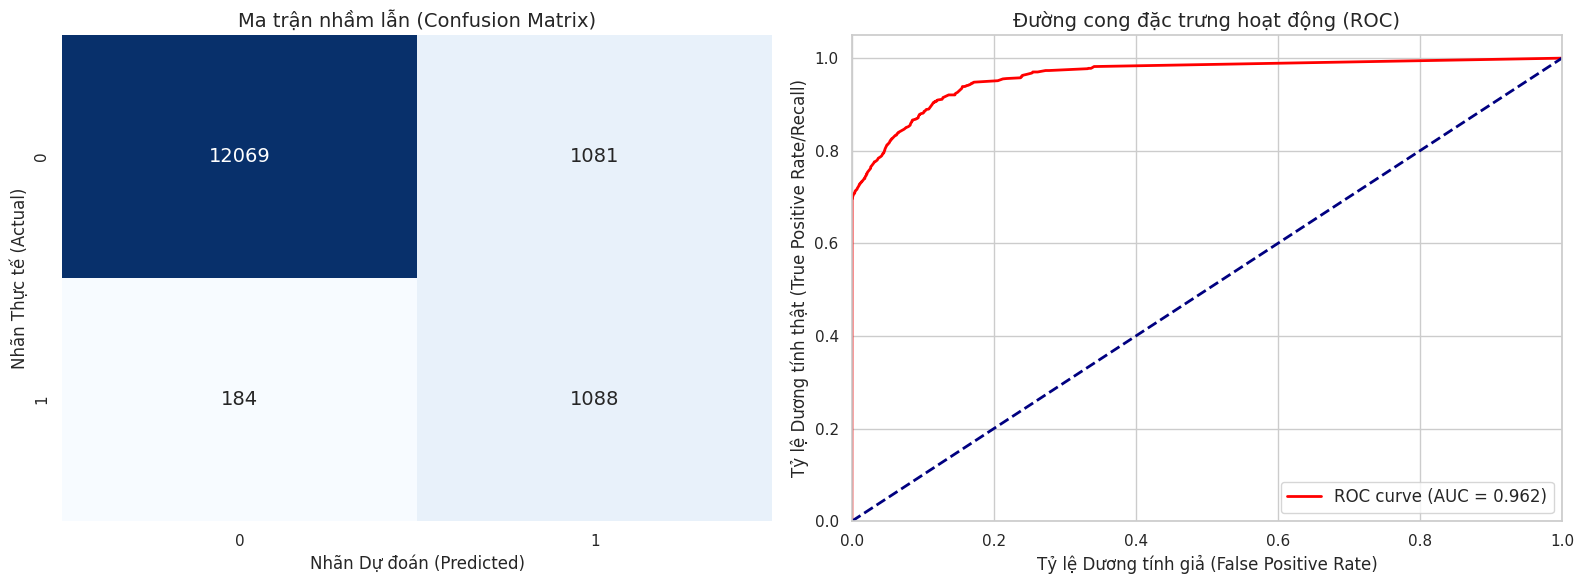

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns


predictions = predict(X_test.values, my_optimized_tree)
probabilities = predict_proba(X_test.values, my_optimized_tree) # Lấy xác suất

# In báo cáo y khoa (Report)
print("\nBáo cáo phân loại (Classification Report):")
print(classification_report(y_test, predictions))

# Trực quan hóa Confusion Matrix
plt.figure(figsize=(16, 6))

plt.subplot(1, 2, 1)
cm = confusion_matrix(y_test, predictions)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, annot_kws={"size": 14})
plt.title('Ma trận nhầm lẫn (Confusion Matrix)', fontsize=14)
plt.xlabel('Nhãn Dự đoán (Predicted)', fontsize=12)
plt.ylabel('Nhãn Thực tế (Actual)', fontsize=12)

# Trực quan hóa đường cong ROC
plt.subplot(1, 2, 2)
fpr, tpr, thresholds = roc_curve(y_test, probabilities[:, 1])
auc_score = roc_auc_score(y_test, probabilities[:, 1])

plt.plot(fpr, tpr, color='red', lw=2, label=f'ROC curve (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tỷ lệ Dương tính giả (False Positive Rate)', fontsize=12)
plt.ylabel('Tỷ lệ Dương tính thật (True Positive Rate/Recall)', fontsize=12)
plt.title('Đường cong đặc trưng hoạt động (ROC)', fontsize=14)
plt.legend(loc="lower right", fontsize=12)

plt.tight_layout()
plt.show()

In [ ]:
def print_tree(tree, feature_names=None, spacing=""):
    """Hàm in cấu trúc cây quyết định ra màn hình để báo cáo"""
    if "value" in tree:
        print(spacing + f"Dự đoán: Lớp {tree['value']} | Xác suất: {np.round(tree['proba'], 2)}")
        return

    feat_name = feature_names[tree['feature_index']] if feature_names is not None else f"Feature {tree['feature_index']}"

    print(spacing + f"[{feat_name} <= {tree['threshold']:.4f}]")

    print(spacing + "--> True:")
    print_tree(tree["left"], feature_names, spacing + "  ")

    print(spacing + "--> False:")
    print_tree(tree["right"], feature_names, spacing + "  ")


print_tree(my_optimized_tree, feature_names=X_train.columns.tolist())

In [ ]:
import pickle

model_filename = 'optimized_decision_tree.pkl'

with open(model_filename, 'wb') as file:
    pickle.dump(my_optimized_tree, file)
